C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


   Row ID        Order ID  Order Date   Ship Date Ship Mode Customer ID  \
0    4102  US-2019-102288  2019-06-23  2020-06-19       TNT    ZC-21910   
1    9293  CA-2019-124114  2019-03-02  2020-03-02       DHL    RS-19765   
2    8659  CA-2018-168361  2018-06-25  2019-06-21       TNT    KB-16600   
3    4712  CA-2016-112403  2016-03-31  2017-03-31       DHL    JO-15280   
4    2107  US-2016-152723  2016-09-26  2017-09-26       DHL    HG-14965   

      Customer Name    Segment Country/Region   Tỉnh Thành         Vùng Miền  \
0  Zuschuss Carroll   Consumer       Viet Nam      Đắk Lắk        Miền Trung   
1    Roland Schwarz  Corporate       Viet Nam  Hồ Chí Minh  Miền Đông Nam Bộ   
2       Ken Brennan  Corporate       Viet Nam     Hà Giang          Miền Bắc   
3     Jas O'Carroll   Consumer       Viet Nam  Hồ Chí Minh  Miền Đông Nam Bộ   
4     Henry Goldwyn  Corporate       Viet Nam      Hà Tỉnh        Miền Trung   

        Product ID         Category Sub-Category  \
0  OFF-AP-100029

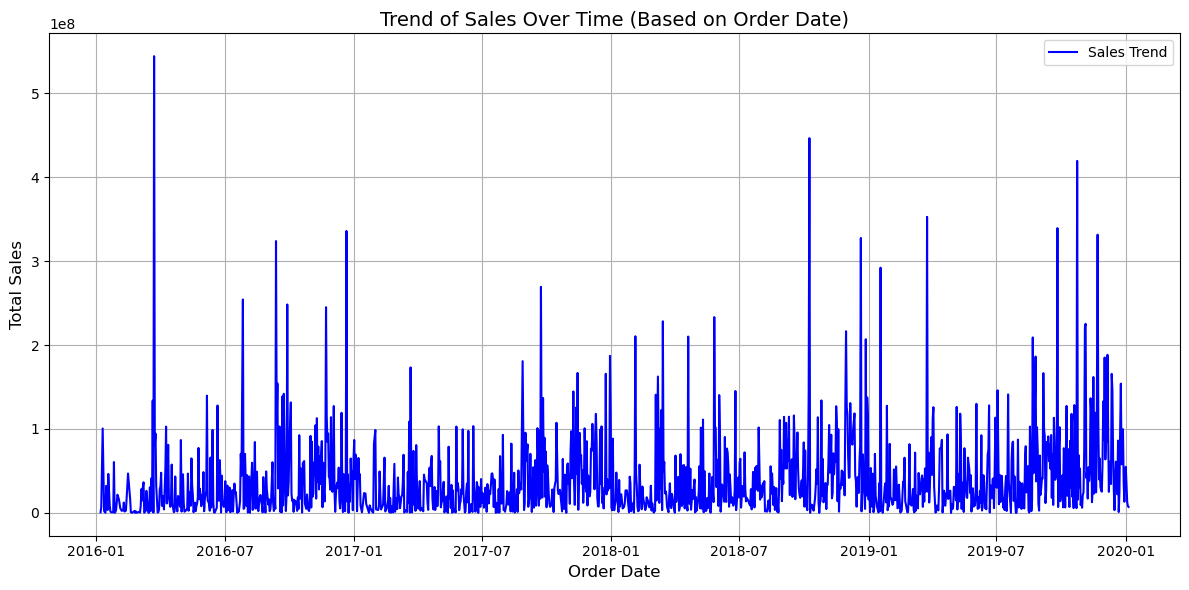

Data has been exported to C:\Users\User\Downloads\Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx


In [203]:
# Xử lý dữ liệu (làm sạch dữ liệu)
import pandas as pd
import matplotlib.pyplot as plt
import os
# Xác định thư mục người dùng (thư mục Downloads)
user_directory = os.path.expanduser("~")

# Đường dẫn đến file Excel trong thư mục Downloads
input_file = os.path.join(user_directory, 'Downloads', 'Bài tập lớn KTDL DN_Dữ liệu gốc.xlsx')

# Tải dữ liệu từ file Excel
dataframes = pd.read_excel(input_file, sheet_name=None, engine='openpyxl')

# Lấy sheet đầu tiên (giả sử đây là sheet cần thiết)
df = dataframes[list(dataframes.keys())[0]]

# Hiển thị vài dòng đầu để hiểu cấu trúc dữ liệu
print(df.head())

# Kiểm tra các giá trị thiếu, dòng trùng và dữ liệu không hợp lệ trong các cột chỉ định
missing_values = df[['Order Date', 'Ship Date', 'Product Name', 'Category']].isnull().sum()
duplicate_rows = df.duplicated().sum()
invalid_dates = {
    'Order Date': pd.to_datetime(df['Order Date'], errors='coerce').isnull().sum(),
    'Ship Date': pd.to_datetime(df['Ship Date'], errors='coerce').isnull().sum()
}

# In kết quả
print("Missing values:")
print(missing_values)
print("Number of duplicate rows:", duplicate_rows)
print("Invalid dates:")
print(invalid_dates)

# Chuẩn hóa cột 'Tỉnh Thành' (ví dụ chuẩn hóa tên)
df['Tỉnh Thành'] = df['Tỉnh Thành'].str.strip().str.title()

# Chuyển đổi 'Order Date' và 'Ship Date' sang định dạng datetime
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%Y-%m-%d', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%Y-%m-%d', errors='coerce')

# Tạo các trường mới
df['Delivery Time'] = (df['Ship Date'] - df['Order Date']).dt.days
df['Year-Month'] = df['Order Date'].dt.to_period('M')

# Hiển thị dữ liệu đã được cập nhật
print(df.head())

# Tính tổng doanh thu theo ngày ('Order Date')
sales_trend = df.groupby('Order Date')['Sales'].sum().reset_index()

# Vẽ đồ thị xu hướng doanh thu theo thời gian
plt.figure(figsize=(12, 6))
plt.plot(sales_trend['Order Date'], sales_trend['Sales'], label='Sales Trend', color='blue')
plt.title('Trend of Sales Over Time (Based on Order Date)', fontsize=14)
plt.xlabel('Order Date', fontsize=12)
plt.ylabel('Total Sales', fontsize=12)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

# Xuất dữ liệu đã làm sạch và cập nhật vào file Excel mới
output_file = os.path.join(user_directory, 'Downloads', 'Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx')
df.to_excel(output_file, index=False)

print("Data has been exported to", output_file)

In [135]:
import pandas as pd

# Định nghĩa hàm đọc tất cả các sheet từ tệp Excel
def read_all_sheets_from_excel(filepath):
    return pd.read_excel(filepath, sheet_name=None)  # sheet_name=None đọc tất cả các sheet
    
# Tải dữ liệu từ tệp Excel
FILEPATH = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
dataframes = read_all_sheets_from_excel(FILEPATH)

# Giả sử dữ liệu liên quan nằm trong 'Sheet1'
df = dataframes['Sheet1']

# In thử để kiểm tra
print(df.head())

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


   Row ID        Order ID Order Date  Ship Date Ship Mode Customer ID  \
0    4102  US-2019-102288 2019-06-23 2020-06-19       TNT    ZC-21910   
1    9293  CA-2019-124114 2019-03-02 2020-03-02       DHL    RS-19765   
2    8659  CA-2018-168361 2018-06-25 2019-06-21       TNT    KB-16600   
3    4712  CA-2016-112403 2016-03-31 2017-03-31       DHL    JO-15280   
4    2107  US-2016-152723 2016-09-26 2017-09-26       DHL    HG-14965   

      Customer Name    Segment Country/Region   Tỉnh Thành  ...  \
0  Zuschuss Carroll   Consumer       Viet Nam      Đắk Lắk  ...   
1    Roland Schwarz  Corporate       Viet Nam  Hồ Chí Minh  ...   
2       Ken Brennan  Corporate       Viet Nam     Hà Giang  ...   
3     Jas O'Carroll   Consumer       Viet Nam  Hồ Chí Minh  ...   
4     Henry Goldwyn  Corporate       Viet Nam      Hà Tỉnh  ...   

        Product ID         Category Sub-Category  \
0  OFF-AP-10002906  Office Supplies      Binders   
1  OFF-BI-10004022  Office Supplies      Binders   
2 

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Kết quả đã được lưu vào file 'C:/Users/User/Downloads/doanh_thu_summary.xlsx'


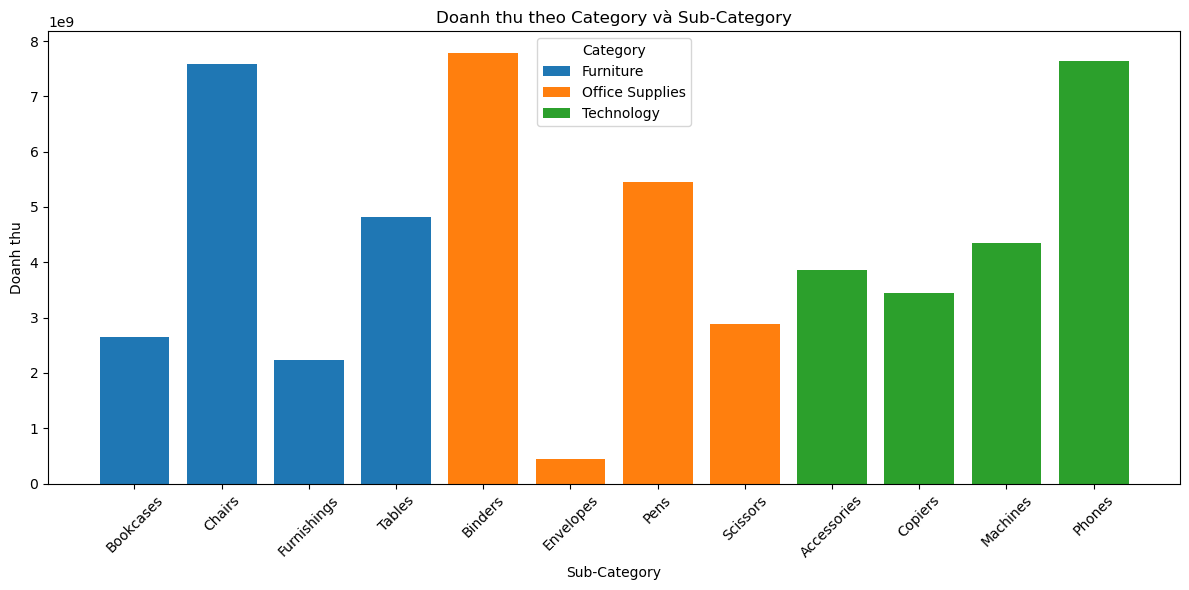

Hoàn thành


In [205]:
# Tổng hợp doanh thu theo Category và Sub-Category. Vẽ biểu đồ cột thể hiện doanh thu từng danh mục sản phẩm.
# Nhập các thư viện cần thiết
import pandas as pd
import matplotlib.pyplot as plt

# Đọc dữ liệu từ file Excel
FILEPATH = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'

# Đọc tất cả các sheet trong tệp Excel
dataframes = pd.read_excel(FILEPATH, sheet_name=None)

# Giả sử dữ liệu liên quan nằm trong 'Sheet1'
df = dataframes['Sheet1']

# Nhóm theo Category và Sub-Category và tính tổng doanh thu (Sales)
revenue_summary = df.groupby(['Category', 'Sub-Category'])['Sales'].sum().reset_index()

# Tạo biểu đồ cột cho doanh thu theo Category và Sub-Category
plt.figure(figsize=(12, 6))
for category in revenue_summary['Category'].unique():
    subset = revenue_summary[revenue_summary['Category'] == category]
    plt.bar(subset['Sub-Category'], subset['Sales'], label=category)
plt.title('Doanh thu theo Category và Sub-Category')
plt.xlabel('Sub-Category')
plt.ylabel('Doanh thu')
plt.xticks(rotation=45)
plt.legend(title='Category')
plt.tight_layout()

# Lưu biểu đồ vào file PNG
plt.savefig('doanh_thu_theo_category_subcategory.png')

# Lưu tóm tắt doanh thu vào tệp Excel
output_file = 'C:/Users/User/Downloads/doanh_thu_summary.xlsx'  # Đường dẫn đến thư mục Downloads
revenue_summary.to_excel(output_file, index=False)

print(f"Kết quả đã được lưu vào file '{output_file}'")

# Hiển thị biểu đồ
plt.show()
print('Hoàn thành')

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


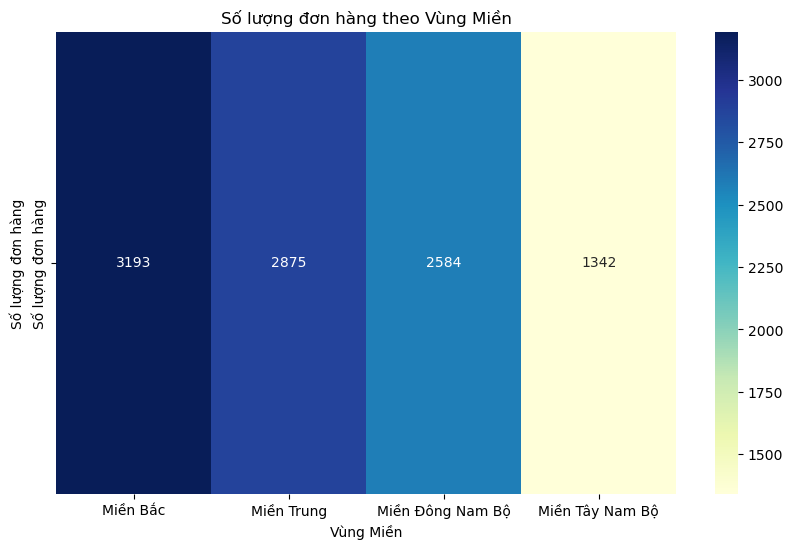

Dữ liệu đã được lưu vào file C:/Users/User/Downloads/so_luong_don_hang_theo_vung_mien (2).xlsx
Hoàn thành


In [195]:
# Phân tích số lượng đơn hàng theo các Vùng Miền. Sử dụng bản đồ nhiệt (heatmap) để thể hiện kết quả.
# Nhập các thư viện cần thiết
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Đọc tệp Excel và tải dữ liệu
FILEPATH = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
dataframes = read_all_sheets_from_excel(FILEPATH)

# Trích xuất dataframe liên quan
orders_df = dataframes['Sheet1']

# Nhóm theo 'Vùng Miền' và đếm số lượng đơn hàng
order_counts = orders_df['Vùng Miền'].value_counts().reset_index()
order_counts.columns = ['Vùng Miền', 'Số lượng đơn hàng']

# Tạo biểu đồ heatmap
plt.figure(figsize=(10, 6))
sns.heatmap(order_counts.set_index('Vùng Miền').T, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Số lượng đơn hàng theo Vùng Miền')
plt.xlabel('Vùng Miền')
plt.ylabel('Số lượng đơn hàng')
plt.show()  

# Xuất dữ liệu sang file Excel
output_file = 'C:/Users/User/Downloads/so_luong_don_hang_theo_vung_mien (2).xlsx'  # Đường dẫn đến thư mục Downloads
order_counts.to_excel(output_file, index=False)

print(f'Dữ liệu đã được lưu vào file {output_file}')
print('Hoàn thành')

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


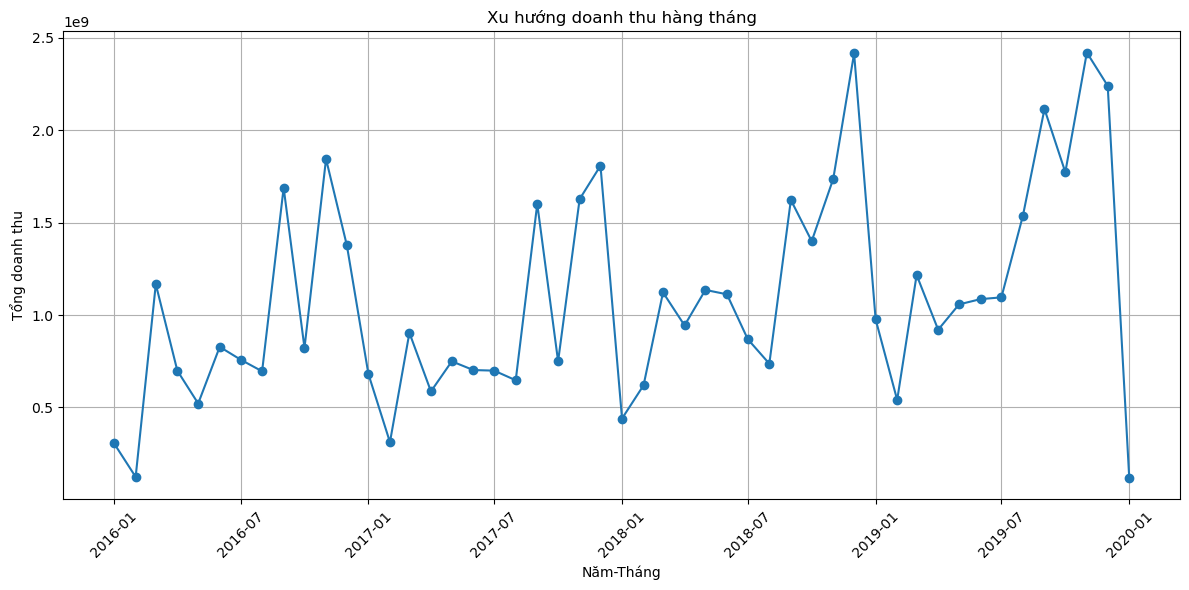

Dữ liệu đã được lưu vào file doanh_thu_hang_thang (2).xlsx
Hoàn thành


In [143]:
# Tổng quan doanh thu hàng tháng: Vẽ biểu đồ đường thể hiện xu hướng doanh thu theo thời gian (Year-Month).
# Đọc tệp Excel và chuẩn bị phân tích xu hướng doanh thu hàng tháng.
import pandas as pd
import matplotlib.pyplot as plt

# Tải dữ liệu từ tệp Excel
FILEPATH = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
dataframes = read_all_sheets_from_excel(FILEPATH)

# Trích xuất bảng dữ liệu liên quan
sales_data = dataframes['Sheet1']

# Chuyển cột 'Year-Month' sang kiểu dữ liệu datetime và tính tổng doanh thu theo tháng
sales_data['Year-Month'] = pd.to_datetime(sales_data['Year-Month'])
monthly_revenue = sales_data.groupby('Year-Month')['Sales'].sum().reset_index()

# Vẽ biểu đồ xu hướng doanh thu hàng tháng
plt.figure(figsize=(12, 6))
plt.plot(monthly_revenue['Year-Month'], monthly_revenue['Sales'], marker='o')
plt.title('Xu hướng doanh thu hàng tháng')
plt.xlabel('Năm-Tháng')
plt.ylabel('Tổng doanh thu')
plt.xticks(rotation=45)
plt.grid()
plt.tight_layout()
plt.show()

# Xuất dữ liệu doanh thu hàng tháng sang file Excel
output_file_path = 'doanh_thu_hang_thang (2).xlsx'
monthly_revenue.to_excel(output_file_path, index=False)
print(f'Dữ liệu đã được lưu vào file {output_file_path}')
print('Hoàn thành')

In [197]:
# Phân tích tỷ lệ giao hàng đúng hạn theo Ship Mode.
# Import các thư viện cần thiết
import pandas as pd

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
data = pd.read_excel(file_path)

# Đặt ngưỡng giao hàng đúng hạn (ví dụ: dưới hoặc bằng 3 ngày là đúng hạn)
on_time_threshold = 3

# Tạo cột "On Time" để xác định giao hàng đúng hạn
data['On Time'] = (data['Delivery Time'] <= on_time_threshold).astype(int)

# Tính tỷ lệ giao hàng đúng hạn theo "Ship Mode"
on_time_rate = data.groupby('Ship Mode')['On Time'].mean().reset_index()
on_time_rate.columns = ['Ship Mode', 'On Time Rate']

# Hiển thị kết quả
print(on_time_rate)

# Xuất dữ liệu ra file Excel
output_file = 'C:/Users/User/Downloads/on_time_rate_by_ship_mode.xlsx'  # Đường dẫn đến thư mục Downloads
on_time_rate.to_excel(output_file, index=False)

print(f'Kết quả đã được lưu vào file: {output_file}')

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


  Ship Mode  On Time Rate
0       DHL           0.0
1     FEDEX           0.0
2       TNT           0.0
3       UPS           0.0
Kết quả đã được lưu vào file: C:/Users/User/Downloads/on_time_rate_by_ship_mode.xlsx


In [199]:
# Đóng góp doanh thu của từng khu vực (Vùng Miền) và loại sản phẩm (Category
# Import các thư viện cần thiết
import pandas as pd

# Đọc file Excel
file_path = 'C:/Users/User/Downloads/book1_cleaned.xlsx'
data = pd.read_excel(file_path)

# Kiểm tra các cột trong dữ liệu
print([repr(col) for col in data.columns])

# Đảm bảo rằng tên các cột không có ký tự thừa
data.columns = data.columns.str.strip()  # Loại bỏ khoảng trắng thừa

# Tính tổng doanh thu theo từng khu vực và loại sản phẩm
result = data.groupby(['Vùng Miền', 'Category'])['Sales'].sum().reset_index()

# Sắp xếp kết quả theo Vùng Miền và Doanh Thu giảm dần
result = result.sort_values(by=['Vùng Miền', 'Sales'], ascending=[True, False])

# Hiển thị kết quả trong console
print(result)

# Lưu kết quả ra file Excel mới
output_file = 'C:/Users/User/Downloads/doanh_thu_theo_vung_mien_category.xlsx'  # Đường dẫn đến thư mục Downloads
result.to_excel(output_file, index=False)

print(f"Kết quả đã được lưu vào file '{output_file}'")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


["'Row ID'", "'Order ID'", "'Order Date'", "'Ship Date'", "'Ship Mode'", "'Customer ID'", "'Customer Name'", "'Segment'", "'Country/Region'", "'Tỉnh Thành'", "'Vùng Miền'", "'Product ID'", "'Category'", "'Sub-Category'", "'Product Name'", "'Sales'", "'Quantity'", "'Discount'", "'Profit'", "'Year-Month'", "'Delivery Time'"]
           Vùng Miền         Category         Sales
2           Miền Bắc       Technology  6.475442e+09
0           Miền Bắc        Furniture  5.543677e+09
1           Miền Bắc  Office Supplies  4.683470e+09
5         Miền Trung       Technology  5.768521e+09
3         Miền Trung        Furniture  5.289722e+09
4         Miền Trung  Office Supplies  5.006589e+09
8    Miền Tây Nam Bộ       Technology  2.919696e+09
7    Miền Tây Nam Bộ  Office Supplies  2.324755e+09
6    Miền Tây Nam Bộ        Furniture  2.281413e+09
10  Miền Đông Nam Bộ  Office Supplies  4.563629e+09
9   Miền Đông Nam Bộ        Furniture  4.160261e+09
11  Miền Đông Nam Bộ       Technology  4.131194e+09

In [207]:
# Xác định khách hàng top doanh thu và sản phẩm bán chạy nhất.
# Import các thư viện cần thiết
import pandas as pd

# Đọc file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
data = pd.read_excel(file_path)

# Kiểm tra các cột trong dữ liệu
print([repr(col) for col in data.columns])

# Loại bỏ khoảng trắng thừa trong tên cột
data.columns = data.columns.str.strip()

# Kiểm tra nếu các cột cần thiết tồn tại
required_columns = ['Customer Name', 'Product Name', 'Sales', 'Quantity']
if not all(col in data.columns for col in required_columns):
    raise ValueError(f"Thiếu các cột cần thiết trong dữ liệu: {', '.join(set(required_columns) - set(data.columns))}")
    
# Xác định khách hàng top doanh thu
top_customers = data.groupby('Customer Name')['Sales'].sum().reset_index()
top_customers = top_customers.sort_values(by='Sales', ascending=False).head(10)

# Xác định sản phẩm bán chạy nhất
best_selling_products = data.groupby('Product Name')['Quantity'].sum().reset_index()
best_selling_products = best_selling_products.sort_values(by='Quantity', ascending=False).head(10)

# Hiển thị kết quả trong console
print(result)

# Lưu kết quả vào file Excel với nhiều sheet
output_file = 'C:/Users/User/Downloads/top_khach_hang_san_pham (2).xlsx'  # Đường dẫn đến thư mục Downloads

with pd.ExcelWriter(output_file) as writer:
    top_customers.to_excel(writer, sheet_name='Top Khách Hàng', index=False)
    best_selling_products.to_excel(writer, sheet_name='Sản Phẩm Bán Chạy', index=False)

print(f"Kết quả đã được lưu vào file '{output_file}'")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


["'Row ID'", "'Order ID'", "'Order Date'", "'Ship Date'", "'Ship Mode'", "'Customer ID'", "'Customer Name'", "'Segment'", "'Country/Region'", "'Tỉnh Thành'", "'Vùng Miền'", "'Product ID'", "'Category'", "'Sub-Category'", "'Product Name'", "'Sales'", "'Quantity'", "'Discount'", "'Profit'", "'Year-Month'", "'Delivery Time'"]
           Vùng Miền         Category         Sales
2           Miền Bắc       Technology  6.475442e+09
0           Miền Bắc        Furniture  5.543677e+09
1           Miền Bắc  Office Supplies  4.683470e+09
5         Miền Trung       Technology  5.768521e+09
3         Miền Trung        Furniture  5.289722e+09
4         Miền Trung  Office Supplies  5.006589e+09
8    Miền Tây Nam Bộ       Technology  2.919696e+09
7    Miền Tây Nam Bộ  Office Supplies  2.324755e+09
6    Miền Tây Nam Bộ        Furniture  2.281413e+09
10  Miền Đông Nam Bộ  Office Supplies  4.563629e+09
9   Miền Đông Nam Bộ        Furniture  4.160261e+09
11  Miền Đông Nam Bộ       Technology  4.131194e+09

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


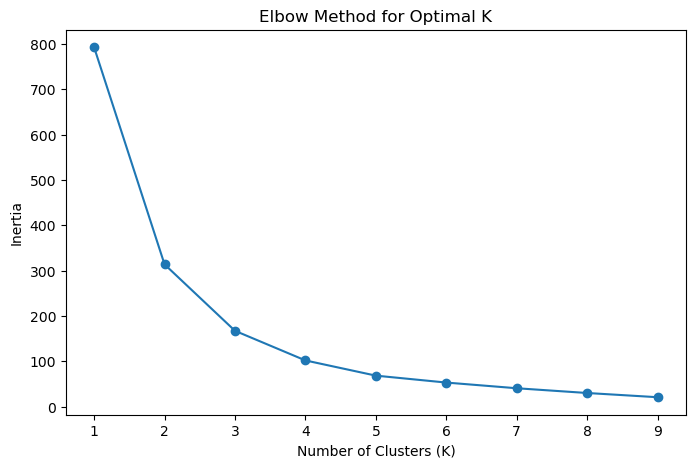

  Customer ID        Sales  Cluster
0    AA-10315  127961880.0        2
1    AA-10375   24296970.0        0
2    AA-10480   41181776.0        0
3    AA-10645  116999505.0        2
4    AB-10015   20381588.0        0


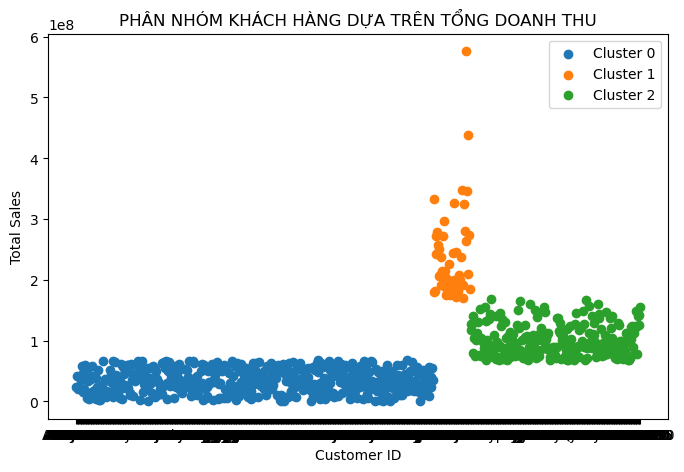

Kết quả phân nhóm khách hàng đã được lưu vào file 'C:/Users/User/Downloads/phan_nhom_khach_hang.xlsx'


In [209]:
# Phân nhóm khách hàng dựa trên tổng doanh thu của khách hàng
# Import các thư viện cần thiết
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/book1_cleaned.xlsx'
data = pd.read_excel(file_path)

# Tính tổng doanh thu (Sales) cho từng Customer ID
customer_sales = data.groupby('Customer ID')['Sales'].sum().reset_index()

# Chuẩn hóa dữ liệu (Standardization)
scaler = StandardScaler()
customer_sales_scaled = scaler.fit_transform(customer_sales[['Sales']])

# Tìm số cụm tối ưu bằng phương pháp Elbow
inertia = []
K_range = range(1, 10)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(customer_sales_scaled)
    inertia.append(kmeans.inertia_)
    
# Vẽ biểu đồ Elbow
plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o')
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.show()

# Áp dụng K-Means với số cụm K = 3
optimal_k = 3  
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
customer_sales['Cluster'] = kmeans.fit_predict(customer_sales_scaled)

# Hiển thị kết quả
print(customer_sales.head())

# Vẽ biểu đồ phân cụm
plt.figure(figsize=(8, 5))
for cluster in range(optimal_k):
    cluster_data = customer_sales[customer_sales['Cluster'] == cluster]
    plt.scatter(cluster_data['Customer ID'], cluster_data['Sales'], label=f'Cluster {cluster}')
plt.title('PHÂN NHÓM KHÁCH HÀNG DỰA TRÊN TỔNG DOANH THU')
plt.xlabel('Customer ID')
plt.ylabel('Total Sales')
plt.legend()
plt.show()

# Lưu kết quả phân nhóm khách hàng vào file Excel
output_file = 'C:/Users/User/Downloads/phan_nhom_khach_hang.xlsx'  # Đường dẫn đến thư mục Downloads
customer_sales.to_excel(output_file, index=False)

print(f"Kết quả phân nhóm khách hàng đã được lưu vào file '{output_file}'")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Dữ liệu ban đầu:
   Row ID        Order ID Order Date  Ship Date Ship Mode Customer ID  \
0    4102  US-2019-102288 2019-06-23 2020-06-19       TNT    ZC-21910   
1    9293  CA-2019-124114 2019-03-02 2020-03-02       DHL    RS-19765   
2    8659  CA-2018-168361 2018-06-25 2019-06-21       TNT    KB-16600   
3    4712  CA-2016-112403 2016-03-31 2017-03-31       DHL    JO-15280   
4    2107  US-2016-152723 2016-09-26 2017-09-26       DHL    HG-14965   

      Customer Name    Segment Country/Region   Tỉnh Thành  ...  \
0  Zuschuss Carroll   Consumer       Viet Nam      Đắk Lắk  ...   
1    Roland Schwarz  Corporate       Viet Nam  Hồ Chí Minh  ...   
2       Ken Brennan  Corporate       Viet Nam     Hà Giang  ...   
3     Jas O'Carroll   Consumer       Viet Nam  Hồ Chí Minh  ...   
4     Henry Goldwyn  Corporate       Viet Nam      Hà Tỉnh  ...   

        Product ID         Category Sub-Category  \
0  OFF-AP-10002906  Office Supplies      Binders   
1  OFF-BI-10004022  Office Supplies  

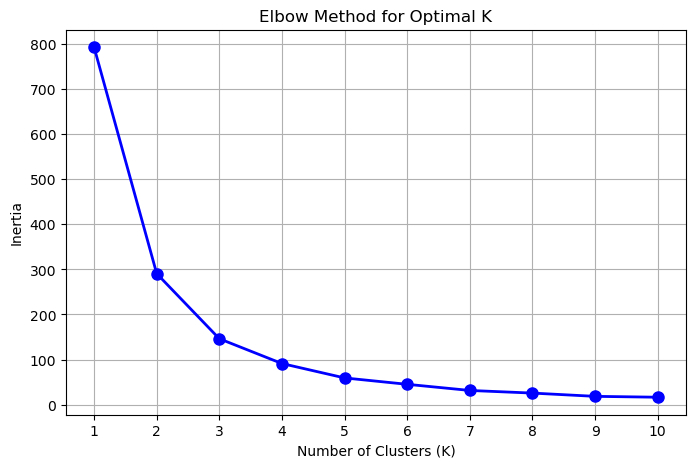


Kết quả phân cụm:
  Customer ID  Order Count  Cluster
0    AA-10315           11        2
1    AA-10375           15        2
2    AA-10480           12        2
3    AA-10645           18        0
4    AB-10015            6        1


C:\Users\User\AppData\Local\Temp\ipykernel_41480\3641563025.py:57: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


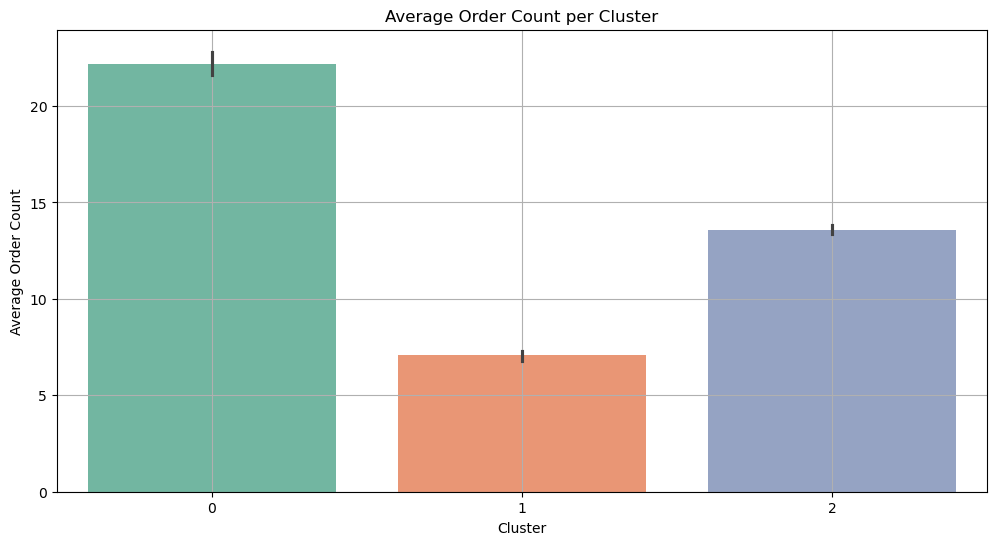

Data with clusters has been exported to C:/Users/User/Downloads/Orders_Per_Customer_Clustered.xlsx


In [157]:
# Phân nhóm khách hàng dựa trên số lượng đơn hàng mà khách hàng đã thực hiện.
# Import các thư viện cần thiết
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
df = pd.read_excel(file_path)

# Kiểm tra dữ liệu
print("Dữ liệu ban đầu:")
print(df.head())

# Tính số lượng đơn hàng của từng khách hàng
orders_per_customer = df.groupby('Customer ID').size().reset_index(name='Order Count')

# Kiểm tra dữ liệu sau khi tính toán
print("\nSố lượng đơn hàng của từng khách hàng:")
print(orders_per_customer.head())

# Chuẩn hóa dữ liệu (StandardScaler giúp chuẩn hóa dữ liệu trước khi phân cụm)
scaler = StandardScaler()
scaled_data = scaler.fit_transform(orders_per_customer[['Order Count']])

# Tìm số cụm tối ưu bằng phương pháp Elbow
inertia = []
k_values = range(1, 11)  # Thử nghiệm từ 1 đến 10 cụm
for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)
    
# Vẽ biểu đồ Elbow
plt.figure(figsize=(8, 5))
plt.plot(k_values, inertia, 'o-', color='blue', markersize=8, linewidth=2)
plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.xticks(k_values)
plt.grid()
plt.show()

# Áp dụng K-Means với số cụm tối ưu 
optimal_k = 3  
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
orders_per_customer['Cluster'] = kmeans.fit_predict(scaled_data)

# Hiển thị kết quả phân cụm
print("\nKết quả phân cụm:")
print(orders_per_customer.head())

# Vẽ biểu đồ phân cụm
plt.figure(figsize=(12, 6))
sns.barplot(
    x='Cluster', y='Order Count', data=orders_per_customer, 
    estimator='mean', palette='Set2'
)
plt.title('Average Order Count per Cluster')
plt.xlabel('Cluster')
plt.ylabel('Average Order Count')
plt.grid()
plt.show()

# Xuất kết quả phân cụm vào file Excel mới
output_file = 'C:/Users/User/Downloads/Orders_Per_Customer_Clustered.xlsx'
orders_per_customer.to_excel(output_file, index=False)
print(f"Data with clusters has been exported to {output_file}")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Đặc điểm từng nhóm khách hàng sau khi phân cụm:
   Cluster  Avg_Total_Sales  Avg_Order_Count  Total_Customers Customer_Type
0        0     2.176963e+08        21.121212               66           VIP
1        1     3.255830e+07         8.063260              411          Thấp
2        2     8.037643e+07        16.727848              316    Trung bình


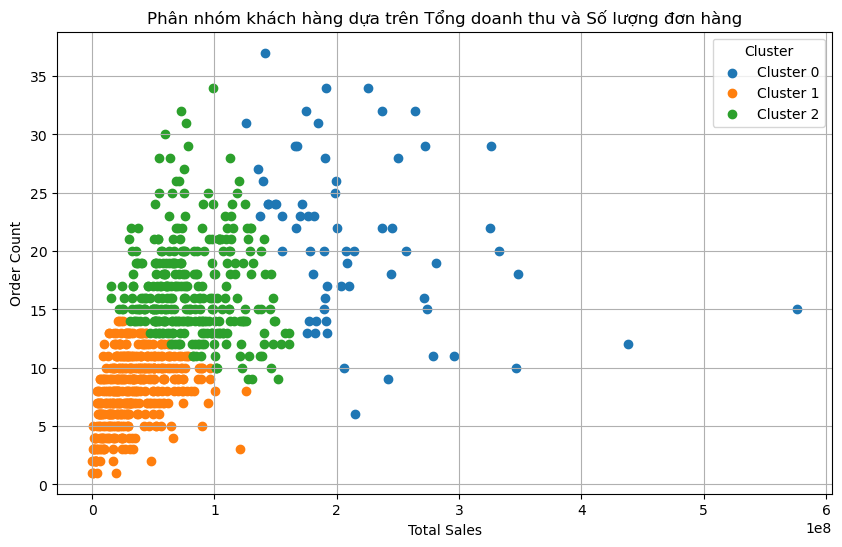

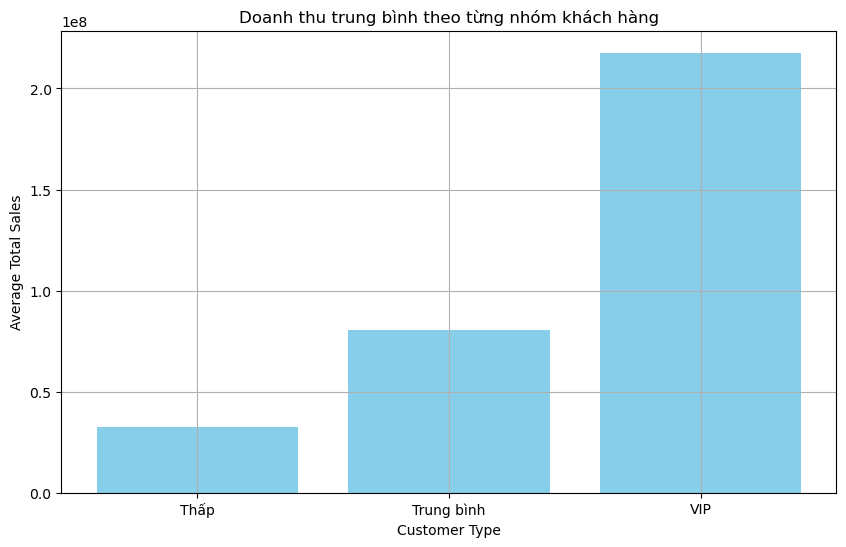

Results have been exported to C:/Users/User/Downloads/Customer_Segmentation_Result.xlsx


In [161]:
# Xác định đặc điểm từng nhóm khách hàng sau khi phân cụm (vd: nhóm khách hàng VIP, nhóm khách hàng trung bình).
# Import các thư viện cần thiết
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/book1_cleaned.xlsx'
data = pd.read_excel(file_path)

# Tính tổng doanh thu (Sales) và số lượng đơn hàng cho từng khách hàng
customer_data = data.groupby('Customer ID').agg(
    Total_Sales=('Sales', 'sum'), 
    Order_Count=('Order ID', 'count')  # Đếm số lượng đơn hàng
).reset_index()
# Chuẩn hóa dữ liệu (StandardScaler)
scaler = StandardScaler()
customer_data_scaled = scaler.fit_transform(customer_data[['Total_Sales', 'Order_Count']])
# Áp dụng K-Means để phân cụm (giả sử số cụm tối ưu là 3)
optimal_k = 3
kmeans = KMeans(n_clusters=optimal_k, random_state=42)
customer_data['Cluster'] = kmeans.fit_predict(customer_data_scaled)
# Xác định đặc điểm từng nhóm khách hàng
cluster_summary = customer_data.groupby('Cluster').agg(
    Avg_Total_Sales=('Total_Sales', 'mean'),
    Avg_Order_Count=('Order_Count', 'mean'),
    Total_Customers=('Customer ID', 'count')
).reset_index()
# Xác định nhãn nhóm khách hàng (VIP, Trung bình, Thấp) dựa trên doanh thu trung bình
def classify_group(row, max_sales, min_sales):
    if row['Avg_Total_Sales'] == max_sales:
        return 'VIP'
    elif row['Avg_Total_Sales'] == min_sales:
        return 'Thấp'
    else:
        return 'Trung bình'
# Tìm giá trị doanh thu trung bình cao nhất và thấp nhất
max_sales = cluster_summary['Avg_Total_Sales'].max()
min_sales = cluster_summary['Avg_Total_Sales'].min()
# Gắn nhãn loại khách hàng
cluster_summary['Customer_Type'] = cluster_summary.apply(
    classify_group, axis=1, max_sales=max_sales, min_sales=min_sales
)
# Hiển thị kết quả đặc điểm từng cụm
print("Đặc điểm từng nhóm khách hàng sau khi phân cụm:")
print(cluster_summary)
# Vẽ biểu đồ minh họa kết quả phân cụm
plt.figure(figsize=(10, 6))
for cluster in range(optimal_k):
    cluster_data = customer_data[customer_data['Cluster'] == cluster]
    plt.scatter(
        cluster_data['Total_Sales'], 
        cluster_data['Order_Count'], 
        label=f'Cluster {cluster}'
    )
plt.title('Phân nhóm khách hàng dựa trên Tổng doanh thu và Số lượng đơn hàng')
plt.xlabel('Total Sales')
plt.ylabel('Order Count')
plt.legend(title='Cluster')
plt.grid()
plt.show()
# Biểu đồ đặc điểm nhóm
plt.figure(figsize=(10, 6))
cluster_summary.sort_values(by='Customer_Type', inplace=True)
plt.bar(cluster_summary['Customer_Type'], cluster_summary['Avg_Total_Sales'], color='skyblue')
plt.title('Doanh thu trung bình theo từng nhóm khách hàng')
plt.xlabel('Customer Type')
plt.ylabel('Average Total Sales')
plt.grid()
plt.show()

# Xuất kết quả phân cụm vào file Excel mới
output_file = 'C:/Users/User/Downloads/Customer_Segmentation_Result.xlsx'
with pd.ExcelWriter(output_file) as writer:
    customer_data.to_excel(writer, sheet_name='Customer Data with Clusters', index=False)
    cluster_summary.to_excel(writer, sheet_name='Cluster Summary', index=False)
print(f"Results have been exported to {output_file}")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Phân tích doanh thu theo Danh mục và Phân mục con:
                                     Sales        Profit  Quantity
Category        Sub-Category                                      
Office Supplies Binders       7.786505e+09  1.262414e+09     10703
Technology      Phones        7.643952e+09  1.023862e+09      3289
Furniture       Chairs        7.579574e+09  6.115738e+08      2356
Office Supplies Pens          5.454888e+09  6.169768e+08      4558
Furniture       Tables        4.822077e+09 -4.076861e+08      1241
Technology      Machines      4.352489e+09  7.784941e+07       440
                Accessories   3.859267e+09  9.645426e+08      2976
                Copiers       3.439145e+09  1.279210e+09       234
Office Supplies Scissors      2.888535e+09  7.558828e+08      5825
Furniture       Bookcases     2.642240e+09 -7.986879e+07       868


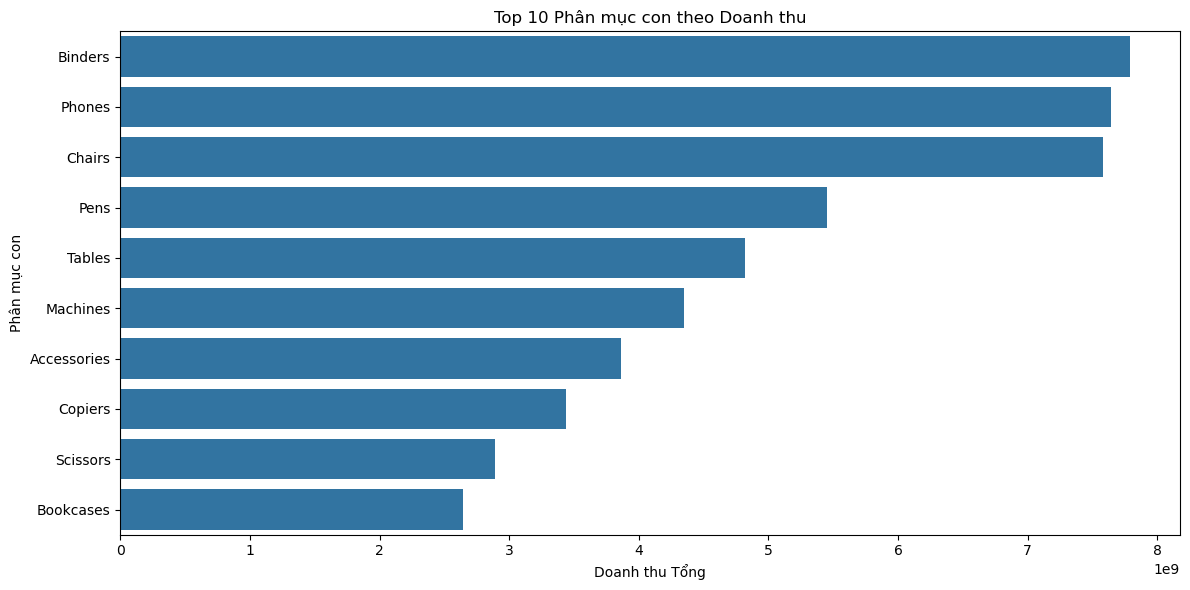

Dữ liệu phân tích doanh thu đã được xuất vào C:/Users/User/Downloads/sales_by_category.xlsx


C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\workbook\child.py:99: UserWarning: Title is more than 31 characters. Some applications may not be able to read the file
  warnings.warn("Title is more than 31 characters. Some applications may not be able to read the file")
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\writer\excel.py:292: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  workbook.properties.modified = datetime.datetime.utcnow()


In [101]:
# Khai phá luật kết hợp
# Nhập các thư viện cần thiết
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc dữ liệu
df = pd.read_excel('C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx', engine='openpyxl')

# Phân tích doanh thu cơ bản
sales_by_category = df.groupby(['Category', 'Sub-Category']).agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).round(2)

print("Phân tích doanh thu theo Danh mục và Phân mục con:")
print(sales_by_category.sort_values('Sales', ascending=False).head(10))

# Tạo đồ thị
plt.figure(figsize=(12, 6))
sns.barplot(data=df.groupby('Sub-Category')['Sales'].sum().reset_index().sort_values('Sales', ascending=False).head(10), 
            x='Sales', y='Sub-Category')
plt.title('Top 10 Phân mục con theo Doanh thu')
plt.xlabel('Doanh thu Tổng')
plt.ylabel('Phân mục con')
plt.tight_layout()
plt.show()

# Xuất dữ liệu phân tích doanh thu vào file Excel
output_file = 'C:/Users/User/Downloads/sales_by_category.xlsx'

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    sales_by_category.to_excel(writer, sheet_name='Doanh thu theo Danh mục và Phân mục con', index=True)

print(f"Dữ liệu phân tích doanh thu đã được xuất vào {output_file}")


In [211]:
# Khai phá các luật kết hợp
# Import các thư viện cần thiết
import pandas as pd
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
data = pd.read_excel(file_path)

# Xem qua dữ liệu
print("Dữ liệu ban đầu:")
print(data.head())

# Thêm cột kết hợp Category và Sub-Category
data['Category_Sub'] = data['Category'] + ' - ' + data['Sub-Category']

# Tạo bảng giao dịch: mỗi hàng là một Order ID, mỗi cột là một Category_Sub
basket = (
    data.groupby(['Order ID', 'Category_Sub'])['Product ID']
    .count()
    .unstack()
    .reset_index()
    .fillna(0)
    .set_index('Order ID')
)

# Biến đổi dữ liệu thành dạng nhị phân (0/1): Có mua (1), Không mua (0)
basket = basket.applymap(lambda x: x > 0).astype(bool)

# Hiển thị dữ liệu sau khi chuyển đổi
print("\nDữ liệu sau khi xử lý nhị phân (bao gồm Category + Sub-Category):")
print(basket.head())

# Áp dụng thuật toán Apriori để tìm các tập phổ biến
frequent_itemsets = apriori(basket, min_support=0.01, use_colnames=True)

# Hiển thị các tập phổ biến
print("\nCác tập phổ biến:")
print(frequent_itemsets)

# Tạo các quy luật kết hợp từ các tập phổ biến
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=0.1, num_itemsets=len(frequent_itemsets))
# Hiển thị các quy luật
print("\nCác quy luật mua hàng thường xuyên:")
print(rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

# Lọc ra các quy luật cụ thể liên quan đến một Category_Sub cụ thể
target_category_sub = "Office Supplies - Binders"  # Ví dụ: Office Supplies - Binders

# Lọc các quy luật liên quan đến target_category_sub
rules_filtered = rules[
    rules['antecedents'].apply(lambda x: target_category_sub in x) |
    rules['consequents'].apply(lambda x: target_category_sub in x)
]

# Kiểm tra và in các quy luật liên quan
if rules_filtered.empty:
    print(f"\nKhông tìm thấy quy luật liên quan đến '{target_category_sub}'.")
else:
    print(f"\nCác quy luật liên quan đến '{target_category_sub}':")
    print(rules_filtered[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

# Lưu kết quả ra file Excel
output_path = 'C:/Users/User/Downloads/Khai_pha_luat_ket_hop.xlsx'

# Chỉ lưu các quy luật liên quan đến target_category_sub
rules_filtered.to_excel(output_path, index=False)
print(f"\nCác quy luật liên quan đã được lưu vào file: {output_path}")


C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Dữ liệu ban đầu:
   Row ID        Order ID Order Date  Ship Date Ship Mode Customer ID  \
0    4102  US-2019-102288 2019-06-23 2020-06-19       TNT    ZC-21910   
1    9293  CA-2019-124114 2019-03-02 2020-03-02       DHL    RS-19765   
2    8659  CA-2018-168361 2018-06-25 2019-06-21       TNT    KB-16600   
3    4712  CA-2016-112403 2016-03-31 2017-03-31       DHL    JO-15280   
4    2107  US-2016-152723 2016-09-26 2017-09-26       DHL    HG-14965   

      Customer Name    Segment Country/Region   Tỉnh Thành  ...  \
0  Zuschuss Carroll   Consumer       Viet Nam      Đắk Lắk  ...   
1    Roland Schwarz  Corporate       Viet Nam  Hồ Chí Minh  ...   
2       Ken Brennan  Corporate       Viet Nam     Hà Giang  ...   
3     Jas O'Carroll   Consumer       Viet Nam  Hồ Chí Minh  ...   
4     Henry Goldwyn  Corporate       Viet Nam      Hà Tỉnh  ...   

        Product ID         Category Sub-Category  \
0  OFF-AP-10002906  Office Supplies      Binders   
1  OFF-BI-10004022  Office Supplies  

C:\Users\User\AppData\Local\Temp\ipykernel_41480\147094816.py:29: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  basket = basket.applymap(lambda x: x > 0).astype(bool)


In [213]:
# Khai phá luật kết hợp
# Import các thư viện cần thiết
import pandas as pd
from mlxtend.frequent_patterns import apriori
from mlxtend.frequent_patterns import association_rules

# Đọc dữ liệu
# Giả định bạn đã đọc dữ liệu từ file CSV
# data = pd.read_csv("path/to/your_file.csv")
# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
data = pd.read_excel(file_path)

# Xem qua dữ liệu
print("Dữ liệu ban đầu:")
print(data.head())

# Chọn các cột cần thiết
df = data[['Order ID', 'Category', 'Sub-Category']]

# Chuẩn bị dữ liệu: Tạo danh sách giao dịch
# Tạo danh sách giao dịch chính xác và loại bỏ cột 'Order ID' ra khỏi nhóm
transactions = df.groupby('Order ID', group_keys=False).apply(
    lambda x: list((x['Category'] + '-' + x['Sub-Category']))
).tolist()

# Chuyển đổi dữ liệu thành dạng one-hot encoding (dạng ma trận giao dịch)
from mlxtend.preprocessing import TransactionEncoder

te = TransactionEncoder()
te_ary = te.fit(transactions).transform(transactions)
df_onehot = pd.DataFrame(te_ary, columns=te.columns_)

# Áp dụng thuật toán Apriori để tìm các tập hợp thường xuyên
frequent_itemsets = apriori(df_onehot, min_support=0.05, use_colnames=True)

# Tạo các luật kết hợp từ tập hợp thường xuyên
rules = association_rules(frequent_itemsets, metric="lift", min_threshold=0.1, num_itemsets=len(frequent_itemsets))

# Lọc ra các luật kết hợp liên quan đến 'Category' và 'Sub-Category'
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(list(x)))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(list(x)))
category_rules = rules[(rules['antecedents_str'].str.contains('Office Supplies')) | 
                       (rules['antecedents_str'].str.contains('Technology'))]

# Hiển thị các luật kết hợp liên quan đến "Office Supplies" hoặc "Technology"
print(category_rules[['antecedents_str', 'consequents_str', 'support', 'confidence', 'lift']])

# Lưu các luật kết hợp liên quan đến "Office Supplies" hoặc "Technology" vào tệp Excel
output_file = 'C:/Users/User/Downloads/Khai_pha_cac_luat_ket_hop_rules.xlsx'
category_rules.to_excel(output_file, index=False)

print(f"Kết quả các luật kết hợp đã được lưu vào file '{output_file}'")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Dữ liệu ban đầu:
   Row ID        Order ID Order Date  Ship Date Ship Mode Customer ID  \
0    4102  US-2019-102288 2019-06-23 2020-06-19       TNT    ZC-21910   
1    9293  CA-2019-124114 2019-03-02 2020-03-02       DHL    RS-19765   
2    8659  CA-2018-168361 2018-06-25 2019-06-21       TNT    KB-16600   
3    4712  CA-2016-112403 2016-03-31 2017-03-31       DHL    JO-15280   
4    2107  US-2016-152723 2016-09-26 2017-09-26       DHL    HG-14965   

      Customer Name    Segment Country/Region   Tỉnh Thành  ...  \
0  Zuschuss Carroll   Consumer       Viet Nam      Đắk Lắk  ...   
1    Roland Schwarz  Corporate       Viet Nam  Hồ Chí Minh  ...   
2       Ken Brennan  Corporate       Viet Nam     Hà Giang  ...   
3     Jas O'Carroll   Consumer       Viet Nam  Hồ Chí Minh  ...   
4     Henry Goldwyn  Corporate       Viet Nam      Hà Tỉnh  ...   

        Product ID         Category Sub-Category  \
0  OFF-AP-10002906  Office Supplies      Binders   
1  OFF-BI-10004022  Office Supplies  

C:\Users\User\AppData\Local\Temp\ipykernel_41480\2069763167.py:23: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  transactions = df.groupby('Order ID', group_keys=False).apply(


In [219]:
# Phân tích doanh thu theo thời gian (Order Date)
# Import các thư viện cần thiết
import pandas as pd

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
data = pd.read_excel(file_path)

# Chuyển đổi cột Order Date sang định dạng ngày tháng
data['Order Date'] = pd.to_datetime(data['Order Date'], errors='coerce')

# Tạo các trường mới để phân tích doanh thu theo thời gian
data['Year'] = data['Order Date'].dt.year 
data['Month'] = data['Order Date'].dt.month  
data['Year-Month'] = data['Order Date'].dt.to_period('M')  
# Tổng doanh thu theo từng năm (cột 'Sales' thay vì 'Doanh Thu')
revenue_by_year = data.groupby('Year')['Sales'].sum().reset_index()

# Tổng doanh thu theo từng tháng trong các năm (cột 'Sales' thay vì 'Doanh Thu')
revenue_by_month = data.groupby(['Year', 'Month'])['Sales'].sum().reset_index()

# Tổng doanh thu theo từng năm-tháng (cột 'Sales' thay vì 'Doanh Thu')
revenue_by_year_month = data.groupby('Year-Month')['Sales'].sum().reset_index()

# In kết quả ra màn hình
print("Tổng doanh thu theo từng năm:")
print(revenue_by_year)

print("\nTổng doanh thu theo từng tháng trong các năm:")
print(revenue_by_month)

print("\nTổng doanh thu theo từng năm-tháng:")
print(revenue_by_year_month)

# Xuất kết quả ra file Excel
output_file = 'C:/Users/User/Downloads/phan_tich_doanh_thu_thoi_gian.xlsx'
with pd.ExcelWriter(output_file) as writer:
    revenue_by_year.to_excel(writer, sheet_name='Doanh Thu Theo Nam', index=False)
    revenue_by_month.to_excel(writer, sheet_name='Doanh Thu Theo Thang', index=False)
    revenue_by_year_month.to_excel(writer, sheet_name='Doanh Thu Theo Nam-Thang', index=False)

print(f"\nKết quả đã được lưu vào file '{output_file}'")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Tổng doanh thu theo từng năm:
   Year         Sales
0  2016  1.083050e+10
1  2017  1.106729e+10
2  2018  1.415383e+10
3  2019  1.697807e+10
4  2020  1.186730e+08

Tổng doanh thu theo từng tháng trong các năm:
    Year  Month         Sales
0   2016      1  3.053280e+08
1   2016      2  1.243501e+08
2   2016      3  1.166922e+09
3   2016      4  6.989347e+08
4   2016      5  5.214142e+08
5   2016      6  8.278081e+08
6   2016      7  7.587837e+08
7   2016      8  6.956406e+08
8   2016      9  1.688573e+09
9   2016     10  8.220540e+08
10  2016     11  1.844190e+09
11  2016     12  1.376505e+09
12  2017      1  6.806795e+08
13  2017      2  3.122488e+08
14  2017      3  9.039022e+08
15  2017      4  5.868508e+08
16  2017      5  7.495229e+08
17  2017      6  7.023691e+08
18  2017      7  6.992052e+08
19  2017      8  6.472152e+08
20  2017      9  1.601164e+09
21  2017     10  7.492415e+08
22  2017     11  1.627045e+09
23  2017     12  1.807847e+09
24  2018      1  4.399913e+08
25  2018   

In [217]:
# Phân tích tỷ lệ giao hàng đúng hạn (chênh lệch giữa Order Date và Ship Date)
# Import các dữ liệu cần thiết
import pandas as pd

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx'
data = pd.read_excel(file_path)

# Chuyển đổi cột Order Date và Ship Date sang định dạng ngày tháng
data['Order Date'] = pd.to_datetime(data['Order Date'], errors='coerce')
data['Ship Date'] = pd.to_datetime(data['Ship Date'], errors='coerce')

# Tính sự chênh lệch ngày giữa Ship Date và Order Date
data['Delivery Time'] = (data['Ship Date'] - data['Order Date']).dt.days

# Gắn nhãn giao hàng đúng hạn hoặc trễ hạn
# Giả định: Nếu Delivery Time <= 2 ngày thì là đúng hạn
data['On Time'] = data['Delivery Time'].apply(lambda x: 'On Time' if x <= 2 else 'Late')

# In dữ liệu với cột mới 'On Time'
print(data[['Order ID', 'Order Date', 'Ship Date', 'Delivery Time', 'On Time']])

# Phân tích tỷ lệ giao hàng đúng hạn
on_time_ratio = data['On Time'].value_counts(normalize=True).reset_index()
on_time_ratio.columns = ['Delivery Status', 'Percentage']

# In kết quả tỷ lệ giao hàng đúng hạn
print("\nTỷ lệ giao hàng đúng hạn:")
print(on_time_ratio)

# Xuất kết quả ra file Excel
output_file = 'C:/Users/User/Downloads/ty_le_giao_hang_dung_han.xlsx'
on_time_ratio.to_excel(output_file, index=False)

print(f"\nKết quả đã được lưu vào file '{output_file}'")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


            Order ID Order Date  Ship Date  Delivery Time On Time
0     US-2019-102288 2019-06-23 2020-06-19            362    Late
1     CA-2019-124114 2019-03-02 2020-03-02            366    Late
2     CA-2018-168361 2018-06-25 2019-06-21            361    Late
3     CA-2016-112403 2016-03-31 2017-03-31            365    Late
4     US-2016-152723 2016-09-26 2017-09-26            365    Late
...              ...        ...        ...            ...     ...
9989  CA-2019-166709 2019-11-22 2020-11-17            361    Late
9990  CA-2019-127180 2019-10-24 2020-10-22            364    Late
9991  CA-2019-140151 2019-03-25 2020-03-23            364    Late
9992  CA-2018-118689 2018-10-09 2019-10-02            358    Late
9993  CA-2016-145317 2016-03-23 2017-03-18            360    Late

[9994 rows x 5 columns]

Tỷ lệ giao hàng đúng hạn:
  Delivery Status  Percentage
0            Late         1.0

Kết quả đã được lưu vào file 'C:/Users/User/Downloads/ty_le_giao_hang_dung_han.xlsx'


In [221]:
# Phân tích doanh thu theo vùng miền
import pandas as pd

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc_cleaned.xlsx' 
data = pd.read_excel(file_path)

# Tổng doanh thu theo từng khu vực
revenue_by_region = data.groupby('Vùng Miền')['Sales'].sum().reset_index()

# Sắp xếp giảm dần theo doanh thu
revenue_by_region = revenue_by_region.sort_values(by='Sales', ascending=False)

# In kết quả
print("Phân tích doanh thu theo khu vực (Vùng Miền):")
print(revenue_by_region)

# Xuất kết quả ra file Excel
output_file = 'C:/Users/User/Downloads/phan_tich_doanh_thu_theo_vung_mien.xlsx'
revenue_by_region.to_excel(output_file, index=False)

print(f"\nPhân tích doanh thu theo khu vực (Vùng Miền) đã được lưu vào file '{output_file}'")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Phân tích doanh thu theo khu vực (Vùng Miền):
          Vùng Miền         Sales
0          Miền Bắc  1.670259e+10
1        Miền Trung  1.606483e+10
3  Miền Đông Nam Bộ  1.285508e+10
2   Miền Tây Nam Bộ  7.525863e+09

Phân tích doanh thu theo khu vực (Vùng Miền) đã được lưu vào file 'C:/Users/User/Downloads/phan_tich_doanh_thu_theo_vung_mien.xlsx'


In [223]:
# Phân tích doah thu theo phân khúc khách hàng (Customer Segment)
# Import các thư viện cần thiết
import pandas as pd

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc.xlsx' 
revenue_by_customer_segment = data.groupby('Segment')['Sales'].sum().reset_index()

# Sắp xếp giảm dần theo doanh thu
revenue_by_customer_segment = revenue_by_customer_segment.sort_values(by='Sales', ascending=False)

# In kết quả ra màn hình
print("Phân tích doanh thu theo phân khúc khách hàng:")
print(revenue_by_customer_segment)

# Xuất kết quả ra file Excel
output_file = 'C:/Users/User/Downloads/phan_tich_doanh_thu_theo_customer_segment.xlsx'
revenue_by_customer_segment.to_excel(output_file, index=False)

print(f"\nPhân tích doanh thu theo khách hàng đã được lưu vào file '{output_file}'")

Phân tích doanh thu theo phân khúc khách hàng:
       Segment         Sales
0     Consumer  2.693863e+10
1    Corporate  1.629082e+10
2  Home Office  9.918922e+09

Phân tích doanh thu theo khách hàng đã được lưu vào file 'C:/Users/User/Downloads/phan_tich_doanh_thu_theo_customer_segment.xlsx'


In [1]:
# Phân tích doanh thu theo Category
# Import các thư viện cần thiết
import pandas as pd

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc.xlsx'
data = pd.read_excel(file_path)

# Tổng doanh thu theo từng loại sản phẩm (Category)
revenue_by_category = data.groupby('Category')['Sales'].sum().reset_index()

# Sắp xếp giảm dần theo doanh thu
revenue_by_category = revenue_by_category.sort_values(by='Sales', ascending=False)

# Xuất kết quả ra file Excel
revenue_by_category.to_excel('doanh_thu_theo_category.xlsx', index=False)

print("Phân tích doanh thu theo loại sản phẩm đã được lưu vào file 'doanh_thu_theo_category.xlsx'")

Phân tích doanh thu theo loại sản phẩm đã được lưu vào file 'doanh_thu_theo_category.xlsx'


In [227]:
# Phân tích doanh thu theo từng loại sản phẩm (Category)
# Import các thư viện cần thiết
import pandas as pd

# Đọc dữ liệu từ file Excel
file_path = 'C:/Users/User/Downloads/Bài tập lớn KTDL DN_Dữ liệu gốc.xlsx'
data = pd.read_excel(file_path)

# Tổng doanh thu theo từng loại sản phẩm (Category)
revenue_by_category = data.groupby('Category')['Sales'].sum().reset_index()

# Sắp xếp giảm dần theo doanh thu
revenue_by_category = revenue_by_category.sort_values(by='Sales', ascending=False)

# In kết quả phân tích doanh thu theo loại sản phẩm
print("Doanh thu theo từng loại sản phẩm:")
print(revenue_by_category)

# Xuất kết quả ra file Excel
output_file = 'C:/Users/User/Downloads/phan_tich_doanh_thu_theo_category.xlsx'
revenue_by_category.to_excel(output_file, index=False)

print(f"\nPhân tích doanh thu theo loại sản phẩm đã được lưu vào file '{output_file}'")

C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()
C:\Users\User\anaconda3\Lib\site-packages\openpyxl\packaging\core.py:99: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  now = datetime.datetime.utcnow()


Doanh thu theo từng loại sản phẩm:
          Category         Sales
2       Technology  1.929485e+10
0        Furniture  1.727507e+10
1  Office Supplies  1.657844e+10

Phân tích doanh thu theo loại sản phẩm đã được lưu vào file 'C:/Users/User/Downloads/phan_tich_doanh_thu_theo_category.xlsx'
